<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Stacked Charts**


Estimated time needed: **45** minutes


In this lab, you will focus on visualizing data specifically using stacked charts. You will use SQL queries to extract the necessary data and apply stacked charts to analyze the composition and comparison within the data.


## Objectives


In this lab, you will perform the following:


- Visualize the composition of data using stacked charts.

- Compare multiple variables across different categories using stacked charts.

- Analyze trends within stacked chart visualizations.


## Setup: Downloading and Loading the Data
**Install the libraries**


In [2]:
!pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 131.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 149.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pandas]


In [3]:
!pip install matplotlib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 123.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 98.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 63.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 107.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]


**Download and Load the Data**


To start, download and load the dataset into a `pandas` DataFrame.



### Step 1: Download the dataset


In [4]:
!wget -O survey-data.csv https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv

Resolving cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)... 169.63.118.104
Connecting to cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)|169.63.118.104|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 159525875 (152M) [text/csv]
Saving to: ‘survey-data.csv’

survey-data.csv     100%[===================>] 152.13M  2.37MB/s    in 59s     

2026-10-12 18:25:52 (2.60 MB/s) - ‘survey-data.csv’ saved [159525875/159525875]


### Step 2: Import necessary libraries and load the dataset


In [6]:
import pandas as pd
import matplotlib.pyplot as plt

### Load the data


In [7]:
df = pd.read_csv("survey-data.csv")

### Display the first few rows of the data to understand its structure


In [8]:
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Task 1: Stacked Chart for Composition of Job Satisfaction Across Age Groups


##### 1. Stacked Chart of Median `JobSatPoints_6` and `JobSatPoints_7` for Different Age Groups


Visualize the composition of job satisfaction scores (`JobSatPoints_6` and `JobSatPoints_7`) across various age groups. This will help in understanding the breakdown of satisfaction levels across different demographics.



                    JobSatPoints_6  JobSatPoints_7
Age                                               
Under 18 years old             1.5             5.0
18-24 years old               15.0            20.0
25-34 years old               20.0            15.0
35-44 years old               20.0            15.0
45-54 years old               20.0            15.0
55-64 years old               20.0            20.0
65 years or older             20.0            15.0

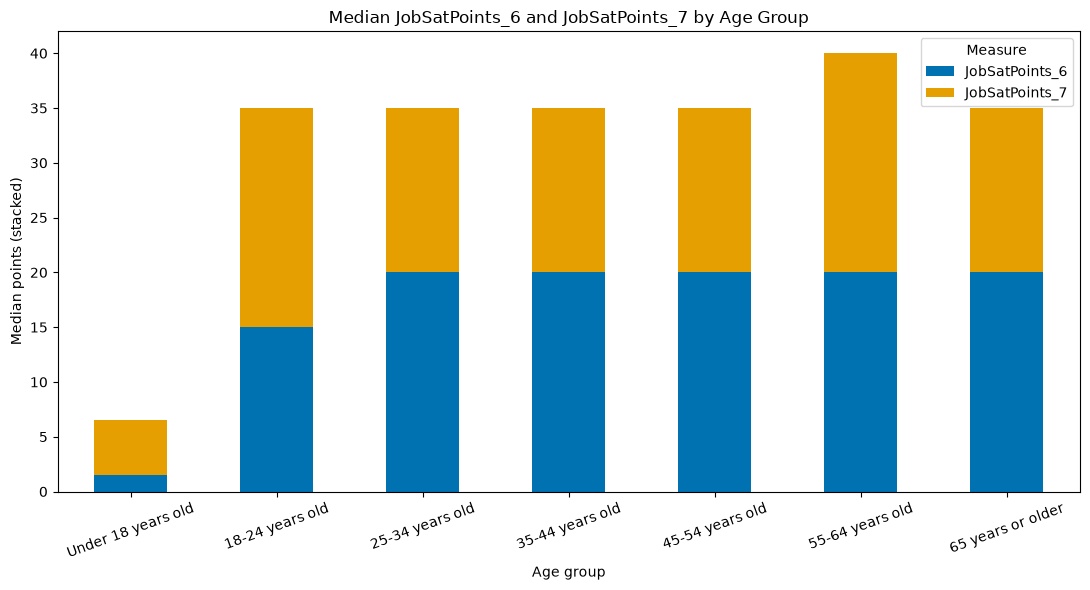

In [7]:
##Write your code here
age_order = ["Under 18 years old", "18-24 years old", "25-34 years old", "35-44 years old",
             "45-54 years old", "55-64 years old", "65 years or older"]

d = df[["Age", "JobSatPoints_6", "JobSatPoints_7"]].copy()
d = d[d["Age"].isin(age_order)]
for c in ["JobSatPoints_6", "JobSatPoints_7"]:
    d[c] = pd.to_numeric(d[c], errors="coerce")

med = d.groupby("Age")[["JobSatPoints_6", "JobSatPoints_7"]].median().reindex(age_order)
print(med)

med.plot(kind="bar", stacked=True, figsize=(11, 6), color=["#0072B2", "#E69F00"])
plt.title("Median JobSatPoints_6 and JobSatPoints_7 by Age Group")
plt.xlabel("Age group")
plt.ylabel("Median points (stacked)")
plt.xticks(rotation=20)
plt.legend(title="Measure")
plt.tight_layout()
plt.show()

##### Stacked Chart of `JobSatPoints_6` and `JobSatPoints_7` for Employment Status


Create a stacked chart to compare job satisfaction (`JobSatPoints_6` and `JobSatPoints_7`) across different employment statuses. This will show how satisfaction varies by employment type.


                                                    JobSatPoints_6  \
Employment                                                           
Employed, full-time                                           20.0   
Independent contractor, freelancer, or self-emp...            15.0   
Student, full-time                                            10.0   
Employed, part-time                                           15.0   
Not employed, but looking for work                            10.0   

                                                    JobSatPoints_7  
Employment                                                          
Employed, full-time                                           15.0  
Independent contractor, freelancer, or self-emp...            15.0  
Student, full-time                                            15.0  
Employed, part-time                                           15.0  
Not employed, but looking for work                            10.0  

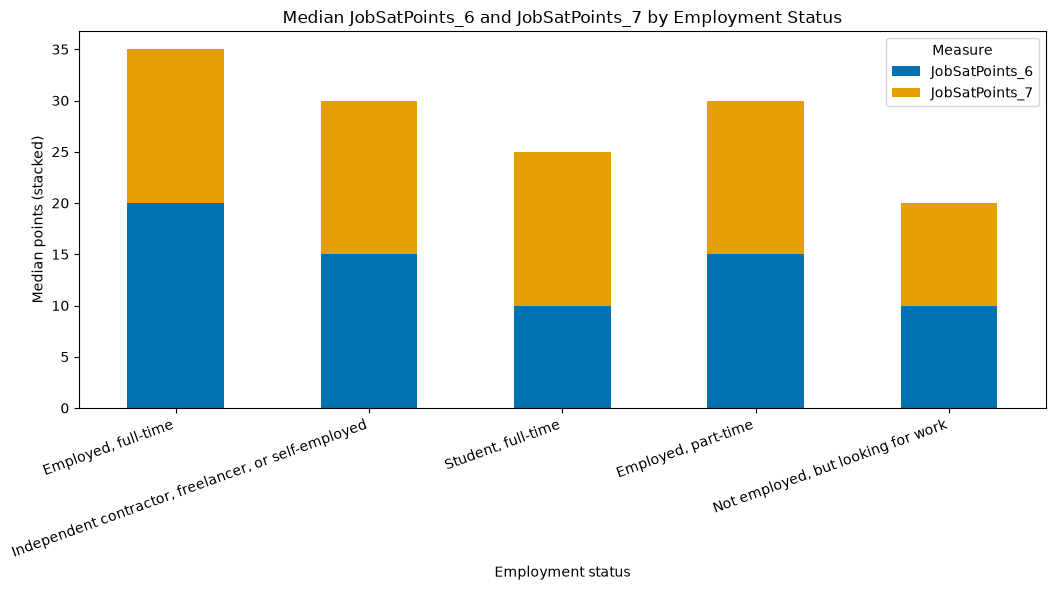

In [8]:
##Write your code here
d = df[["Employment", "JobSatPoints_6", "JobSatPoints_7"]].dropna(subset=["Employment"]).copy()
for c in ["JobSatPoints_6", "JobSatPoints_7"]:
    d[c] = pd.to_numeric(d[c], errors="coerce")
d["Employment"] = d["Employment"].str.split(";")
d = d.explode("Employment")
d["Employment"] = d["Employment"].str.strip()

top_emp = d["Employment"].value_counts().head(5).index.tolist()
med = d[d["Employment"].isin(top_emp)].groupby("Employment")[["JobSatPoints_6", "JobSatPoints_7"]].median().reindex(top_emp)
print(med)

med.plot(kind="bar", stacked=True, figsize=(11, 6), color=["#0072B2", "#E69F00"])
plt.title("Median JobSatPoints_6 and JobSatPoints_7 by Employment Status")
plt.xlabel("Employment status")
plt.ylabel("Median points (stacked)")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Measure")
plt.tight_layout()
plt.show()

### Task 2: Stacked Chart for Compensation and Job Satisfaction by Age Group


##### This stacked chart visualizes the composition of compensation (`ConvertedCompYearly`) and job satisfaction (`JobSatPoints_6`) specifically for respondents aged 30-35.


Overall medians -> comp: 65000.0 | JobSatPoints_6: 20.0
25-34 medians   -> comp: 59825.0 | JobSatPoints_6: 20.0
Index (overall median = 100) -> comp: 92.0 | JobSatPoints_6: 100.0

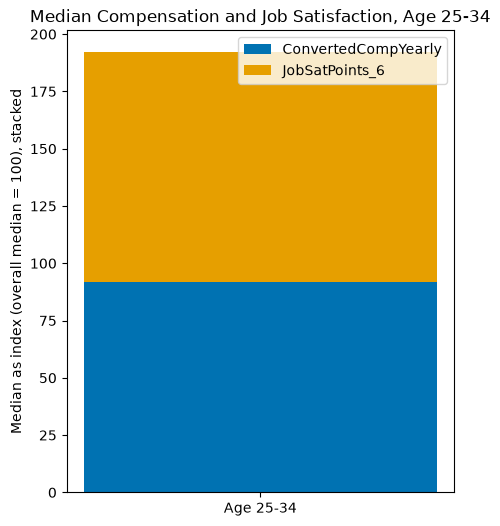

In [9]:
##Write your code here
d = df[["Age", "ConvertedCompYearly", "JobSatPoints_6"]].copy()
d["JobSatPoints_6"] = pd.to_numeric(d["JobSatPoints_6"], errors="coerce")

overall_comp = d["ConvertedCompYearly"].median()
overall_sat = d["JobSatPoints_6"].median()
grp = d[d["Age"] == "25-34 years old"]
comp_med = grp["ConvertedCompYearly"].median()
sat_med = grp["JobSatPoints_6"].median()
print("Overall medians -> comp:", overall_comp, "| JobSatPoints_6:", overall_sat)
print("25-34 medians   -> comp:", comp_med, "| JobSatPoints_6:", sat_med)

comp_idx = comp_med / overall_comp * 100
sat_idx = sat_med / overall_sat * 100
print("Index (overall median = 100) -> comp:", round(comp_idx, 1), "| JobSatPoints_6:", round(sat_idx, 1))

plt.figure(figsize=(5, 6))
plt.bar(["Age 25-34"], [comp_idx], label="ConvertedCompYearly", color="#0072B2")
plt.bar(["Age 25-34"], [sat_idx], bottom=[comp_idx], label="JobSatPoints_6", color="#E69F00")
plt.ylabel("Median as index (overall median = 100), stacked")
plt.title("Median Compensation and Job Satisfaction, Age 25-34")
plt.legend()
plt.show()

##### Stacked Chart of Median Compensation and Job Satisfaction Across Age Group


Compare the median compensation and job satisfaction metrics across different age groups. This helps visualize how compensation and satisfaction levels differ by age.


                    ConvertedCompYearly  JobSatPoints_6
Age                                                    
Under 18 years old               7626.5             1.5
18-24 years old                 25000.0            15.0
25-34 years old                 59825.0            20.0
35-44 years old                 84796.0            20.0
45-54 years old                 99099.0            20.0
55-64 years old                109691.0            20.0
65 years or older              106000.0            20.0
                    ConvertedCompYearly  JobSatPoints_6
Age                                                    
Under 18 years old                 11.7             7.5
18-24 years old                    38.5            75.0
25-34 years old                    92.0           100.0
35-44 years old                   130.5           100.0
45-54 years old                   152.5           100.0
55-64 years old                   168.8           100.0
65 years or older                 163.1         

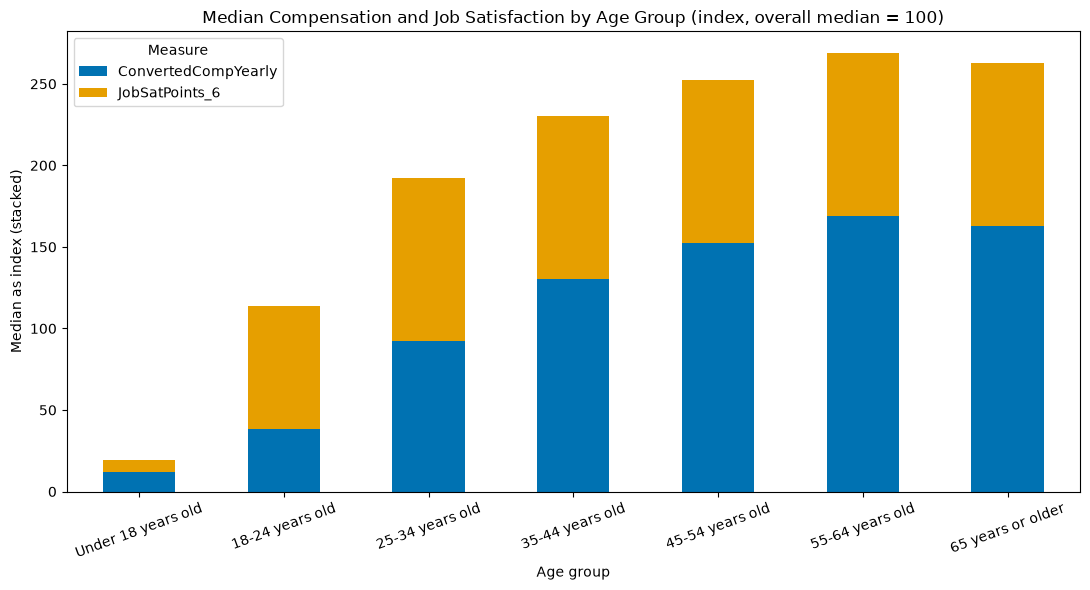

In [10]:
##Write your code here
age_order = ["Under 18 years old", "18-24 years old", "25-34 years old", "35-44 years old",
             "45-54 years old", "55-64 years old", "65 years or older"]

d = df[["Age", "ConvertedCompYearly", "JobSatPoints_6"]].copy()
d = d[d["Age"].isin(age_order)]
d["JobSatPoints_6"] = pd.to_numeric(d["JobSatPoints_6"], errors="coerce")

med = d.groupby("Age")[["ConvertedCompYearly", "JobSatPoints_6"]].median().reindex(age_order)
print(med)

overall = d[["ConvertedCompYearly", "JobSatPoints_6"]].median()
idx = med / overall * 100
print(idx.round(1))

idx.plot(kind="bar", stacked=True, figsize=(11, 6), color=["#0072B2", "#E69F00"])
plt.title("Median Compensation and Job Satisfaction by Age Group (index, overall median = 100)")
plt.xlabel("Age group")
plt.ylabel("Median as index (stacked)")
plt.xticks(rotation=20)
plt.legend(title="Measure", loc="upper left")
plt.tight_layout()
plt.show()

### Task 3: Comparing Data Using Stacked Charts


##### 1. Stacked Chart of Preferred Databases by Age Group




Visualize the top databases that respondents from different age groups wish to learn. Create a stacked chart to show the proportion of each database in each age group.


Database            PostgreSQL  SQLite  MySQL  MongoDB  Redis
Age                                                          
Under 18 years old        25.2    25.3   20.5     18.6   10.4
18-24 years old           31.0    18.5   18.6     18.3   13.5
25-34 years old           34.3    17.6   16.1     15.7   16.3
35-44 years old           35.4    18.8   15.6     13.1   17.1
45-54 years old           35.2    20.7   18.0     12.4   13.8
55-64 years old           34.5    23.5   22.4     11.2    8.4
65 years or older         24.2    29.3   32.0     10.1    4.5

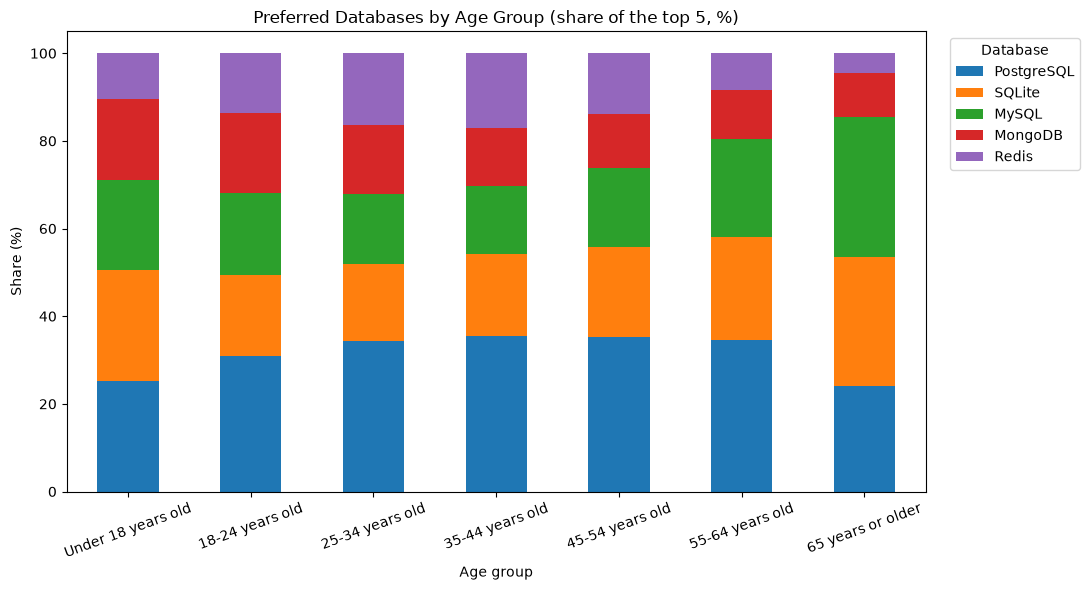

In [9]:
##Write your code here
age_order = ["Under 18 years old", "18-24 years old", "25-34 years old", "35-44 years old",
             "45-54 years old", "55-64 years old", "65 years or older"]

d = df[["Age", "DatabaseWantToWorkWith"]].dropna().copy()
d = d[d["Age"].isin(age_order)]
d["Database"] = d["DatabaseWantToWorkWith"].str.split(";")
d = d.explode("Database").reset_index(drop=True)      # reset_index fixes the duplicate-label error
d["Database"] = d["Database"].str.strip()

top5 = d["Database"].value_counts().head(5).index.tolist()
d = d[d["Database"].isin(top5)]

share = pd.crosstab(d["Age"], d["Database"], normalize="index").reindex(index=age_order, columns=top5) * 100
print(share.round(1))

share.plot(kind="bar", stacked=True, figsize=(11, 6))
plt.title("Preferred Databases by Age Group (share of the top 5, %)")
plt.xlabel("Age group")
plt.ylabel("Share (%)")
plt.xticks(rotation=20)
plt.legend(title="Database", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

##### 2. Stacked Chart of Employment Type by Job Satisfaction


Analyze the distribution of employment types within each job satisfaction level using a stacked chart. This will provide insights into how employment types are distributed across various satisfaction ratings.


Employment
Employed, full-time                                     26231
Independent contractor, freelancer, or self-employed     4275
Employed, part-time                                      1808
Student, full-time                                       1021
Name: count, dtype: int64
Employment  Employed, full-time  \
JobSat                            
0                          81.0   
1                          76.4   
2                          79.2   
3                          78.9   
4                          77.1   
5                          79.0   
6                          79.4   
7                          79.7   
8                          79.1   
9                          79.3   
10                         73.0   

Employment  Independent contractor, freelancer, or self-employed  \
JobSat                                                             
0                                                        11.5      
1                                                      

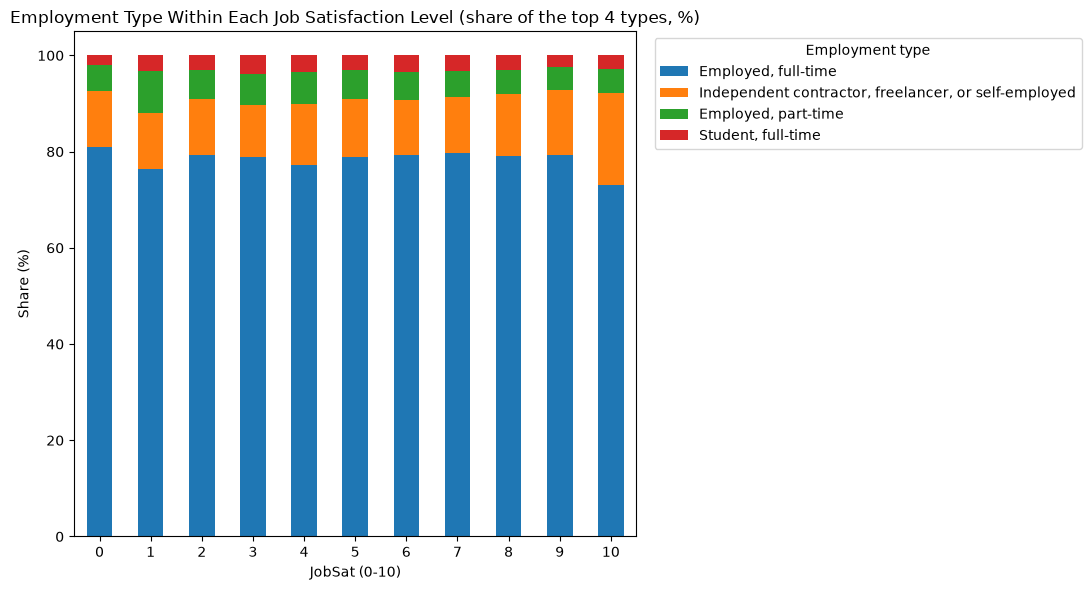

In [10]:
##Write your code here
d = df[["Employment", "JobSat"]].dropna().copy()
d["JobSat"] = pd.to_numeric(d["JobSat"], errors="coerce")
d = d.dropna(subset=["JobSat"])
d["JobSat"] = d["JobSat"].round().astype(int)
d["Employment"] = d["Employment"].str.split(";")
d = d.explode("Employment").reset_index(drop=True)    # same fix here
d["Employment"] = d["Employment"].str.strip()

top_emp = d["Employment"].value_counts().head(4).index.tolist()
print(d["Employment"].value_counts().head(4))
d = d[d["Employment"].isin(top_emp)]

share = pd.crosstab(d["JobSat"], d["Employment"], normalize="index")[top_emp] * 100
print(share.round(1))

share.plot(kind="bar", stacked=True, figsize=(11, 6))
plt.title("Employment Type Within Each Job Satisfaction Level (share of the top 4 types, %)")
plt.xlabel("JobSat (0-10)")
plt.ylabel("Share (%)")
plt.xticks(rotation=0)
plt.legend(title="Employment type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Task 4: Exploring Technology Preferences Using Stacked Charts


##### 1. Stacked Chart for Preferred Programming Languages by Age Group


Analyze how programming language preferences (`LanguageAdmired`) vary across age groups.


Language            JavaScript  Python   SQL  HTML/CSS  TypeScript
Age                                                               
Under 18 years old        23.0    27.6  11.0      25.8        12.6
18-24 years old           21.5    23.5  18.2      20.6        16.2
25-34 years old           21.7    20.3  20.6      19.0        18.3
35-44 years old           22.6    18.6  22.2      20.1        16.5
45-54 years old           22.3    19.6  25.9      19.6        12.5
55-64 years old           22.6    20.5  28.4      19.7         8.8
65 years or older         21.9    25.0  26.3      21.8         4.9

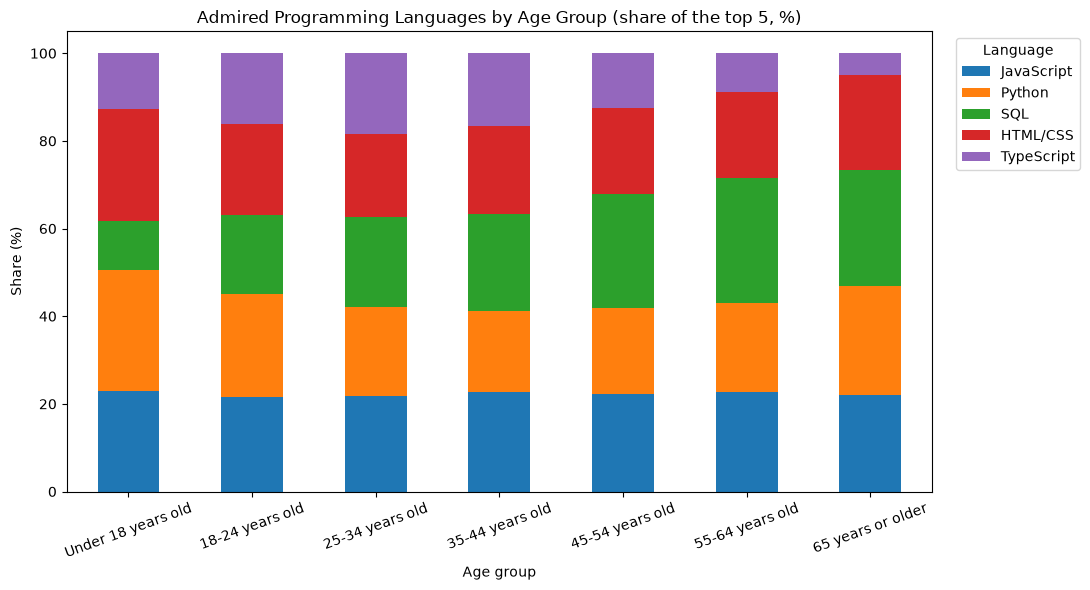

In [10]:
##Write your code here
age_order = ["Under 18 years old", "18-24 years old", "25-34 years old", "35-44 years old",
             "45-54 years old", "55-64 years old", "65 years or older"]

d = df[["Age", "LanguageAdmired"]].dropna().copy()
d = d[d["Age"].isin(age_order)]
d["Language"] = d["LanguageAdmired"].str.split(";")
d = d.explode("Language").reset_index(drop=True)
d["Language"] = d["Language"].str.strip()

top5 = d["Language"].value_counts().head(5).index.tolist()
d = d[d["Language"].isin(top5)]

share = pd.crosstab(d["Age"], d["Language"], normalize="index").reindex(index=age_order, columns=top5) * 100
print(share.round(1))

share.plot(kind="bar", stacked=True, figsize=(11, 6))
plt.title("Admired Programming Languages by Age Group (share of the top 5, %)")
plt.xlabel("Age group")
plt.ylabel("Share (%)")
plt.xticks(rotation=20)
plt.legend(title="Language", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

##### 2. Stacked Chart for Technology Adoption by Employment Type


Explore how admired platforms (`PlatformAdmired`) differ across employment types (e.g., full-time, freelance)


['Amazon Web Services (AWS)', 'Microsoft Azure', 'Google Cloud', 'Cloudflare', 'Firebase']
Platform                                            Amazon Web Services (AWS)  \
Employment                                                                      
Employed, full-time                                                      41.0   
Independent contractor, freelancer, or self-emp...                       34.6   
Student, full-time                                                       25.0   
Employed, part-time                                                      31.6   

Platform                                            Microsoft Azure  \
Employment                                                            
Employed, full-time                                            22.9   
Independent contractor, freelancer, or self-emp...             17.9   
Student, full-time                                             12.7   
Employed, part-time                                            17.9

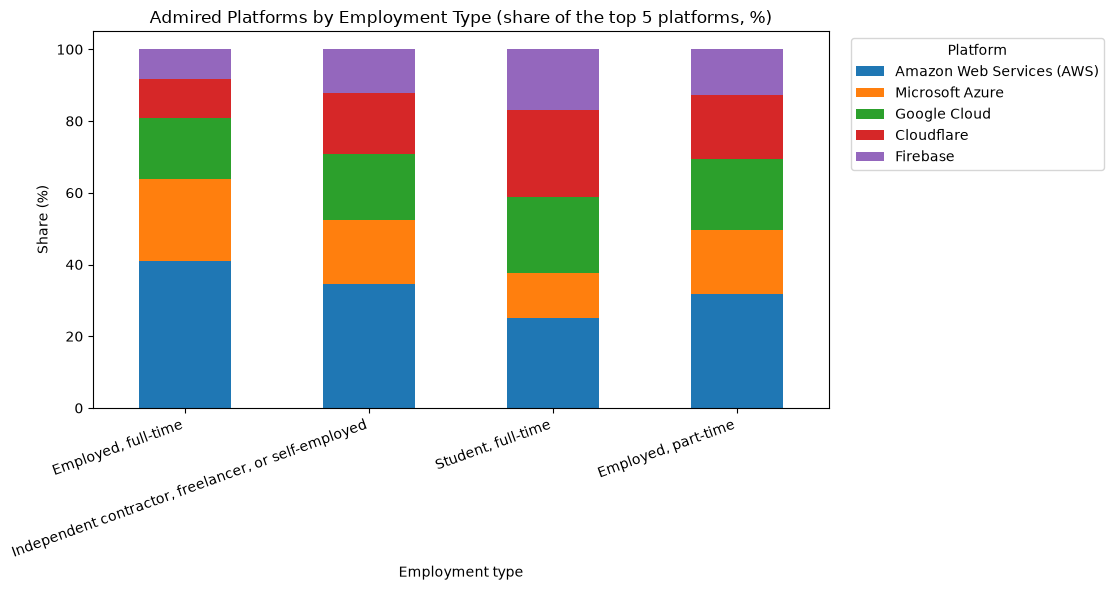

In [9]:
##Write your code here
d = df[["Employment", "PlatformAdmired"]].dropna().copy()
d["Employment"] = d["Employment"].str.split(";")
d = d.explode("Employment").reset_index(drop=True)
d["Employment"] = d["Employment"].str.strip()
d["Platform"] = d["PlatformAdmired"].str.split(";")
d = d.explode("Platform").reset_index(drop=True)
d["Platform"] = d["Platform"].str.strip()

top_emp = d["Employment"].value_counts().head(4).index.tolist()
top_plat = d["Platform"].value_counts().head(5).index.tolist()
print(top_plat)
d = d[d["Employment"].isin(top_emp) & d["Platform"].isin(top_plat)]

share = pd.crosstab(d["Employment"], d["Platform"], normalize="index").reindex(index=top_emp, columns=top_plat) * 100
print(share.round(1))

share.plot(kind="bar", stacked=True, figsize=(11, 6))
plt.title("Admired Platforms by Employment Type (share of the top 5 platforms, %)")
plt.xlabel("Employment type")
plt.ylabel("Share (%)")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Platform", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Final Step: Review


In this lab, you focused on using stacked charts to understand the composition and comparison within the dataset. Stacked charts provided insights into job satisfaction, compensation, and preferred databases across age groups and employment types.


## Summary


After completing this lab, you will be able to:

- Use stacked charts to analyze the composition of data across categories, such as job satisfaction and compensation by age group.

- Compare data across different dimensions using stacked charts, enhancing your ability to communicate complex relationships in the data.

- Visualize distributions across multiple categories, such as employment type by satisfaction, to gain a deeper understanding of patterns within the dataset.


## Author:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


<!--
## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2024-10-28|1.2|Madhusudhan Moole|Updated lab|
|2024-10-16|1.1|Madhusudhan Moole|Updated lab|
|2024-10-15|1.0|Raghul Ramesh|Created lab|
--!>


Copyright © IBM Corporation. All rights reserved.
